# Praktikum 2

In [1]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='black')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

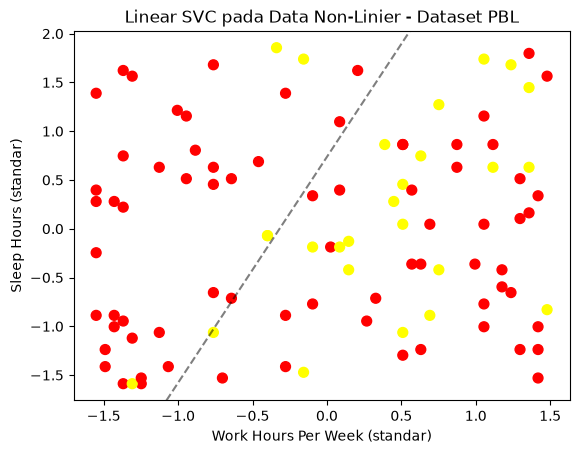

In [3]:
# Data tidak terpisah secara linier dari Dataset PBL (Work_Hours_Per_Week vs Sleep_Hours)
raw_df = pd.read_csv('burnout_dataset1.csv')
df_nl = raw_df[['Work_Hours_Per_Week', 'Sleep_Hours', 'Burnout_Risk']].dropna().sample(n=100, random_state=42)

scaler = StandardScaler()
X = scaler.fit_transform(df_nl[['Work_Hours_Per_Week', 'Sleep_Hours']].to_numpy())
y = (df_nl['Burnout_Risk'] == 'Moderate').astype(int).to_numpy()

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.xlabel('Work Hours Per Week (standar)')
plt.ylabel('Sleep Hours (standar)')
plt.title('Linear SVC pada Data Non-Linier - Dataset PBL')
plt.show()

In [4]:
r = np.exp(-(X**2).sum(1))

In [5]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    plt.figure(figsize=(7, 6))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('Work Hours (standar)')
    ax.set_ylabel('Sleep Hours (standar)')
    ax.set_zlabel('r')
    ax.set_box_aspect(None, zoom=0.85)
    plt.show()

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-1.55053353, -0.88778131],
       [ 0.38839078,  0.86326664],
       [-1.36875938,  0.22121573],
       [ 0.14602524, -0.12899387],
       [ 1.17607878, -0.59593999],
       [-0.94461969,  1.15510797],
       [ 0.14602524, -0.42083519],
       [ 0.20661662,  1.62205409],
       [-0.27811446, -0.88778131],
       [-0.8840283 ,  0.80489838],
       [-0.64166276,  0.51305705],
       [ 0.63075631, -1.23799091],
       [-0.15693169,  1.73879062],
       [ 1.4790357 ,  1.56368583],
       [ 0.08543385,  1.0967397 ],
       [ 1.41844432, -1.52983223],
       [ 0.50957355,  0.86326664],
       [-1.55053353,  0.39632052],
       [-0.27811446, -1.4130957 ],
       [ 0.50957355,  0.04611093],
       [ 1.41844432, -1.00451784],
       [-1.42935076, -1.00451784],
       [ 0.63075631,  0.74653011],
       [ 0.02484247, -0.18736213],
       [-0.33870584,  1.85552715],
       [-1.12639384,  0.62979358],
       [-1.24757661, -1.5882005 ],
       [

In [6]:
clf = SVC(kernel='rbf', C=100.0)
clf.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


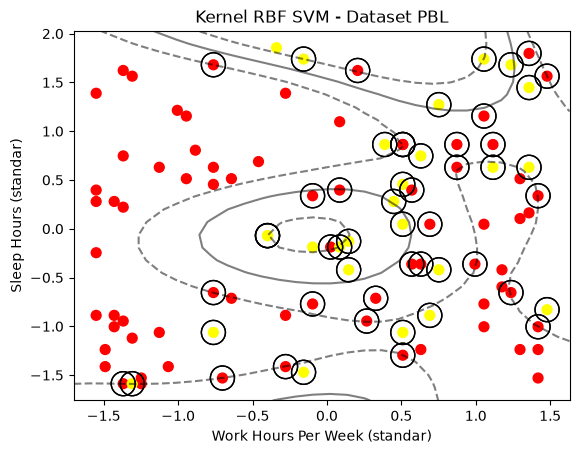

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none', edgecolors='black')
plt.xlabel('Work Hours Per Week (standar)')
plt.ylabel('Sleep Hours (standar)')
plt.title('Kernel RBF SVM - Dataset PBL')
plt.show()